Data and visualization tools loaded successfully!


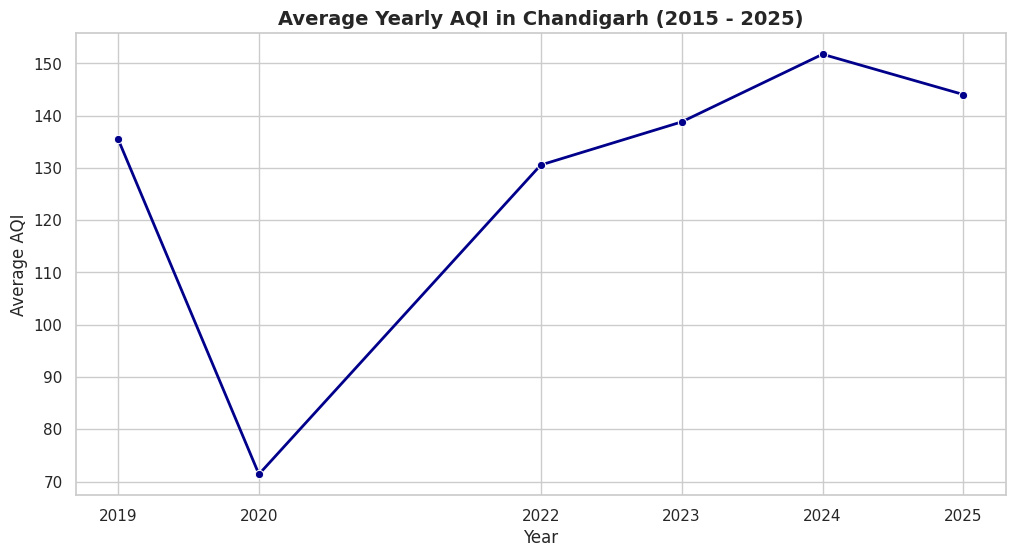

/tmp/ipykernel_1716/1446526007.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=monthly_aqi, x='Month_Name', y='AQI', palette='Reds')


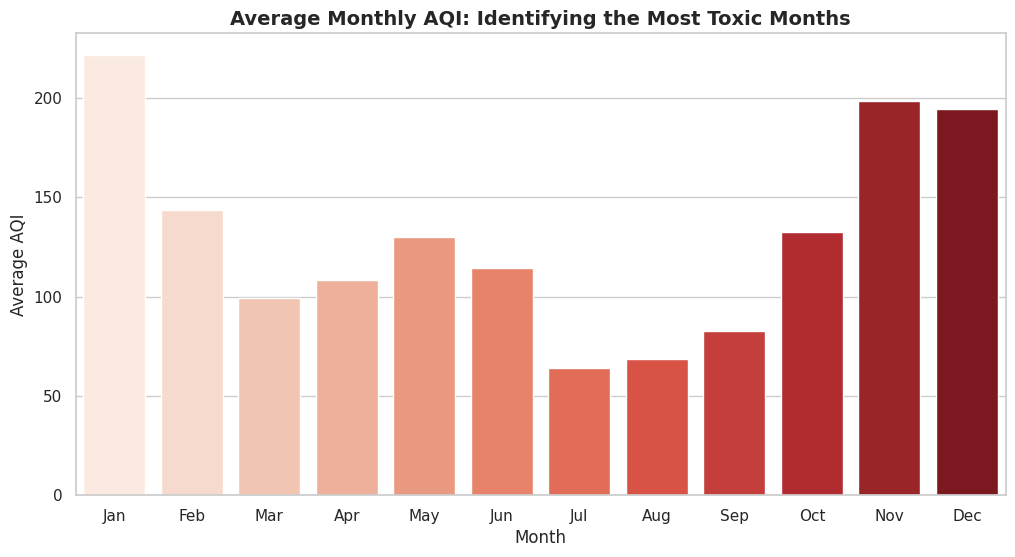

/tmp/ipykernel_1716/1446526007.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=day_type_aqi, x='Day_Type', y='AQI', palette='viridis')


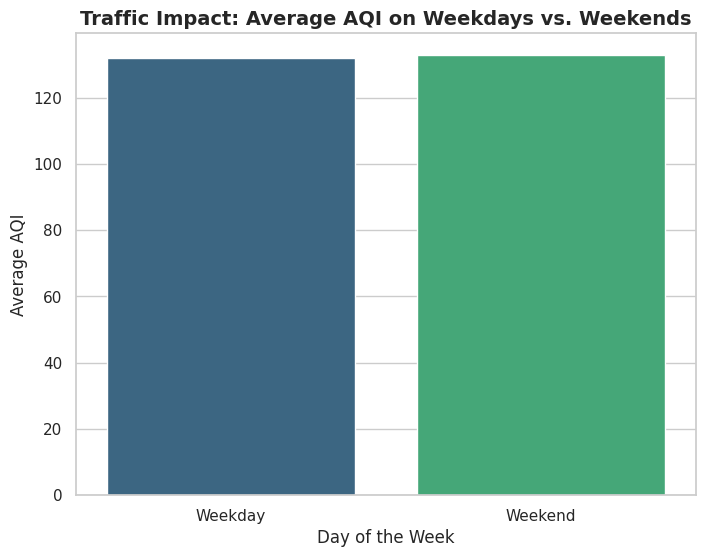

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import calendar

# Loading the cleaned dataset and ensure dates are recognized

df = pd.read_csv('/content/chandigarh temporal features aakrity.csv', parse_dates=['Date'])

# Setting a clean visual style for all the upcoming charts
sns.set_theme(style="whitegrid")
print("Data and visualization tools loaded successfully!")

plt.figure(figsize=(12, 6))
#  day comes first in your dataset!
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, format='mixed')
# Calculating the average AQI for each year
yearly_aqi = df.groupby(df['Date'].dt.year)['AQI'].mean().reset_index()

# Building the line chart
sns.lineplot(data=yearly_aqi, x='Date', y='AQI', marker='o', color='darkblue', linewidth=2)

plt.title('Average Yearly AQI in Chandigarh (2015 - 2025)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Average AQI', fontsize=12)
plt.xticks(yearly_aqi['Date']) # Ensuring all years show up on the bottom axis

plt.show()

plt.figure(figsize=(12, 6))

# Calculating average AQI per month
monthly_aqi = df.groupby(df['Date'].dt.month)['AQI'].mean().reset_index()

# Converting month numbers (1-12) to names (Jan-Dec) for a readable chart
monthly_aqi['Month_Name'] = monthly_aqi['Date'].apply(lambda x: calendar.month_abbr[x])

# Building the bar chart using a color palette that emphasizes high values
sns.barplot(data=monthly_aqi, x='Month_Name', y='AQI', palette='Reds')

plt.title('Average Monthly AQI: Identifying the Most Toxic Months', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average AQI', fontsize=12)

plt.show()

plt.figure(figsize=(8, 6))

# Creating a new column: If the day of the week is 5 (Sat) or 6 (Sun), label it 'Weekend'
df['Day_Type'] = df['Date'].dt.dayofweek.apply(lambda x: 'Weekend' if x >= 5 else 'Weekday')

# Calculating the average AQI for both categories
day_type_aqi = df.groupby('Day_Type')['AQI'].mean().reset_index()

# Building the bar chart
sns.barplot(data=day_type_aqi, x='Day_Type', y='AQI', palette='viridis')

plt.title('Traffic Impact: Average AQI on Weekdays vs. Weekends', fontsize=14, fontweight='bold')
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel('Average AQI', fontsize=12)

plt.show()